# Bagian 2 — Varian 1 — Penentuan k dengan Metode Elbow

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Pertemuan | dikerjakan setelah Pertemuan 12, dipresentasikan Pertemuan 14 |
| Tahap resmi | Tahap 2 — Varian Eksperimen 1 |
| Dikerjakan oleh | **Ashfahani Hasyim**  |
| Berkas yang dibutuhkan | `data_bersih.csv` dari Bagian 1 |
| Luaran wajib | `data/hasil_varian/varian1.json`, `gambar/varian1_elbow.png` |
| Dinilai pada | Progres 2, Pertemuan 14, **35% perorangan** |
| Tenggat | selesai sebelum Pertemuan 14 |

| | |
|---|---|
| Kelompok | 3|
| Paket dataset | laptop_price.csv|
| Nama dan NIM |
Faiz Muzaki Irsyad (2488010047)
Ashfahani Hasyim (2488010070)
Alvin perdiansyah dwi putra ( 2488010019)|

---

## Panduan Bagian 2

> **Ketentuan Varian 1:** *Metode Elbow untuk k = 2 sampai 10, lalu tentukan titik sikunya.*

Bagian ini dikerjakan **Anggota 1 saja**, dan dinilai **perorangan**. Jangan menjalankan Bagian milik anggota lain: riwayat commit dipakai sebagai bukti siapa mengerjakan apa.

**Urutan kerja**

1. Jalankan 2.0 (persiapan).
2. Jalankan 2.1. Sel itu memastikan `data_bersih.csv` sudah ada di folder Drive kelompok.
3. Jalankan 2.2. Perhatikan nilai inertia tiap k dan posisi titik sikunya.
4. **Tulis sendiri** jawaban di 2.3. Interpretasi inilah yang paling banyak membedakan nilai antaranggota.
5. Jalankan 2.4 untuk mengunduh hasil, lalu commit dengan akun GitHub **Anda sendiri**.
6. Kirim `varian1.json` ke Anggota 2. Varian 2 membutuhkannya untuk membandingkan kesimpulan.

**Yang perlu dipahami lebih dulu**

Inertia adalah jumlah kuadrat jarak setiap titik ke pusat klasternya. Nilainya **selalu** turun ketika k dinaikkan, jadi "inertia terkecil" bukan jawaban — kalau k disamakan dengan jumlah baris, inertia menjadi nol dan hasilnya tidak berguna. Yang dicari adalah titik di mana penurunan mulai melandai, karena di situ penambahan klaster berhenti memberi manfaat berarti.

Menunjuk siku dengan mata sering berbeda antarorang. Sel 2.2 memakai cara yang dapat diperiksa ulang: **jarak tegak lurus terjauh** dari garis yang menghubungkan titik k terkecil ke titik k terbesar. Yang dinilai bukan besarnya angka, melainkan apakah titik siku ditentukan dengan cara yang dapat dijelaskan.

Silhouette ikut dihitung di sini, tetapi hanya sebagai metrik pendukung. Dasar Bagian ini adalah inertia.

---

## 2.0 Persiapan — **jalankan setiap kali notebook dibuka**

Sesi Colab menghapus seluruh berkasnya setiap kali runtime dimulai ulang. Karena itu hasil kerja tidak disimpan di sesi Colab, melainkan di **satu folder Google Drive** yang dipakai bersama sepanjang Pertemuan 12 sampai 15. Empat sel di bawah menghubungkan folder itu, memasang pustaka, menulis `alat.py`, dan menyiapkan fungsi pembantu. Keempatnya dijalankan lebih dulu, apa pun yang Anda kerjakan di notebook ini.

`alat.py` berisi fungsi yang dipakai ketiga varian. **Jangan mengubahnya sendiri-sendiri:** kalau satu anggota mengubah isi berkas ini, ketiga varian berhenti sebanding dan tabel perbandingan menjadi tidak sah.

In [21]:
# Folder Drive ini adalah tempat serah-terima antar pertemuan: apa pun yang
# ditulis di sini terbaca kembali oleh notebook pertemuan berikutnya.
import os
import sys
from google.colab import drive

drive.mount('/content/drive')

FOLDER = FOLDER = '/content/drive/MyDrive/ProyekML_KlasteringKMeans'
os.makedirs(FOLDER, exist_ok=True)
os.chdir(FOLDER)      # sejak baris ini, 'data/...' berarti di dalam FOLDER

if FOLDER not in sys.path:
    sys.path.insert(0, FOLDER)   # agar 'import alat' menemukan berkas di folder ini

for d in ('data', 'data/hasil_varian', 'model', 'gambar'):
    os.makedirs(d, exist_ok=True)

print('Folder proyek:', FOLDER)
print('Isi folder   :', sorted(os.listdir()) or '(masih kosong)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder proyek: /content/drive/MyDrive/ProyekML_KlasteringKMeans
Isi folder   : ['data', 'gambar', 'model']


In [22]:
import ast, json, os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)

SEED = 42
ID_COL = 'laptop_ID'        # ganti sesuai kolom identitas dataset kelompok Anda
IQR_PENGALI = 1.5

print('Siap. scikit-learn', sklearn.__version__)
print('Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.')

Siap. scikit-learn 1.6.1
Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.


In [23]:
%%writefile alat.py
"""alat.py -- fungsi bersama ketiga varian. Jangan diubah sendiri-sendiri."""
from __future__ import annotations

import json
import os

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import (calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

SEED = 42
RENTANG_K = range(2, 11)
BERKAS_BERSIH = 'data/data_bersih.csv'
FOLDER_HASIL = 'data/hasil_varian'

# Label dan satuan untuk antarmuka aplikasi (ketentuan Tahap 3: setiap
# masukan harus punya label dan satuan yang dipahami orang luar).
LABEL = {
    'BALANCE': ('Saldo rata-rata', 'USD'),
    'BALANCE_FREQUENCY': ('Keseringan saldo diperbarui', 'skala 0-1'),
    'PURCHASES': ('Total pembelian', 'USD'),
    'ONEOFF_PURCHASES': ('Pembelian sekali bayar', 'USD'),
    'INSTALLMENTS_PURCHASES': ('Pembelian cicilan', 'USD'),
    'CASH_ADVANCE': ('Penarikan tunai', 'USD'),
    'PURCHASES_FREQUENCY': ('Keseringan berbelanja', 'skala 0-1'),
    'ONEOFF_PURCHASES_FREQUENCY': ('Keseringan belanja sekali bayar', 'skala 0-1'),
    'PURCHASES_INSTALLMENTS_FREQUENCY': ('Keseringan belanja cicilan', 'skala 0-1'),
    'CASH_ADVANCE_FREQUENCY': ('Keseringan menarik tunai', 'skala 0-1'),
    'CASH_ADVANCE_TRX': ('Jumlah transaksi tarik tunai', 'kali'),
    'PURCHASES_TRX': ('Jumlah transaksi belanja', 'kali'),
    'CREDIT_LIMIT': ('Limit kartu', 'USD'),
    'PAYMENTS': ('Total pembayaran', 'USD'),
    'MINIMUM_PAYMENTS': ('Pembayaran minimum', 'USD'),
    'PRC_FULL_PAYMENT': ('Proporsi pelunasan penuh', 'skala 0-1'),
    'TENURE': ('Lama berlangganan', 'bulan'),
}


def label_satuan(kolom: str) -> tuple[str, str]:
    return LABEL.get(kolom, (kolom.replace('_', ' ').title(), ''))


def muat_bersih(fitur: list[str] | None = None) -> pd.DataFrame:
    """Membaca data bersih kelompok. Kolom identitas selalu dibuang."""
    df = pd.read_csv(BERKAS_BERSIH)
    # Hanya kolom numerik yang menjadi fitur pembentuk klaster.
    # Kolom identitas seperti CUST_ID tidak membawa informasi kemiripan.
    df = df.select_dtypes(include='number')
    return df[fitur] if fitur else df


def skalakan(df: pd.DataFrame):
    sc = StandardScaler()
    return sc.fit_transform(df), sc


def jalankan_k(X_scaled, rentang=RENTANG_K) -> pd.DataFrame:
    """Menjalankan K-Means untuk tiap k, mengembalikan tabel metrik."""
    baris = []
    for k in rentang:
        km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=SEED)
        lab = km.fit_predict(X_scaled)
        baris.append({
            'k': k,
            'inertia': float(km.inertia_),
            'silhouette': float(silhouette_score(X_scaled, lab)),
            'davies_bouldin': float(davies_bouldin_score(X_scaled, lab)),
            'calinski_harabasz': float(calinski_harabasz_score(X_scaled, lab)),
        })
    return pd.DataFrame(baris)


def titik_siku(ks, inertia) -> int:
    """Titik siku = jarak tegak lurus terjauh dari garis ujung ke ujung."""
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inertia, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    x1, y1, x2, y2 = x_n[0], y_n[0], x_n[-1], y_n[-1]
    jarak = np.abs((y2 - y1) * x_n - (x2 - x1) * y_n + x2 * y1 - y2 * x1)
    jarak /= np.hypot(y2 - y1, x2 - x1)
    return int(x[int(np.argmax(jarak))])


def profil_relatif(df: pd.DataFrame, label) -> pd.DataFrame:
    """Simpangan rata-rata tiap klaster terhadap rata-rata seluruh data,
    dalam satuan simpangan baku. Baris = fitur, kolom = klaster."""
    d = df.copy()
    d['cluster'] = label
    rata = d.drop(columns='cluster').mean()
    sd = d.drop(columns='cluster').std().replace(0, np.nan)
    return ((d.groupby('cluster').mean() - rata) / sd).round(2).T


def nama_otomatis(profil: pd.DataFrame) -> dict[str, str]:
    """Dua fitur dengan simpangan terbesar secara mutlak, beserta arahnya.
    WAJIB diganti mahasiswa dengan nama yang bermakna."""
    nama = {}
    for c in profil.columns:
        kol = profil[c]
        kuat = kol.reindex(kol.abs().sort_values(ascending=False).index)[:2]
        nama[str(int(c))] = ', '.join(
            f'{n} {"tinggi" if v > 0 else "rendah"}' for n, v in kuat.items())
    return nama


def simpan_hasil(nomor: int, isi: dict) -> str:
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    with open(jalur, 'w', encoding='utf-8') as f:
        json.dump(isi, f, indent=2, ensure_ascii=False)
    return jalur


def baca_hasil(nomor: int) -> dict | None:
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    if not os.path.exists(jalur):
        return None
    with open(jalur, encoding='utf-8') as f:
        return json.load(f)

Writing alat.py


In [24]:
def ambil_berkas():
    """Cadangan: unggah berkas manual bila folder Drive tak bisa diakses."""
    from google.colab import files
    for nama in files.upload():
        if nama.startswith('varian') and nama.endswith('.json'):
            tujuan = 'data/hasil_varian/' + nama
        elif nama.endswith('.pkl') or nama == 'segmen.json':
            tujuan = 'model/' + nama
        elif nama.endswith('.png'):
            tujuan = 'gambar/' + nama
        else:
            tujuan = 'data/' + nama
        shutil.move(nama, tujuan)
        print('->', tujuan)


def perlu(*jalur):
    """Memastikan luaran pertemuan sebelumnya sudah ada di folder Drive."""
    kurang = [j for j in jalur if not os.path.exists(j)]
    if not kurang:
        print('Lengkap:', ', '.join(jalur))
        return
    raise FileNotFoundError(
        'Belum ada di folder Drive: ' + ', '.join(kurang) + '. '
        'Jalankan notebook pertemuan sebelumnya sampai selesai. Bila folder '
        'kelompok tidak dapat diakses dari akun Google Anda, jalankan '
        'ambil_berkas() di sel baru untuk mengunggah berkasnya manual.')


print('Folder kerja:', os.getcwd())
print('perlu() dan ambil_berkas() siap dipakai.')

Folder kerja: /content/drive/MyDrive/ProyekML_KlasteringKMeans
perlu() dan ambil_berkas() siap dipakai.


## 2.1 Mengambil berkas yang diperlukan

Sel ini memeriksa berkas yang Anda butuhkan di folder Drive kelompok. Bila ada yang belum dihasilkan, sel berhenti dengan pesan yang menyebut berkasnya. Aman dijalankan berulang kali.

In [26]:
perlu('data/data_bersih.csv')

Lengkap: data/data_bersih.csv


## 2.2 Menjalankan varian 1

VARIAN 1 - PENENTUAN k DENGAN METODE ELBOW (LAPTOP PRICE)
Data bersih kelompok: 1303 baris, 10 fitur

 k  inertia  penurunan  penurunan_persen  silhouette
 2 9544.003        NaN               NaN       0.274
 3 7764.170   1779.832            18.649       0.281
 4 6587.124   1177.046            15.160       0.297
 5 5819.284    767.840            11.657       0.316
 6 5314.916    504.368             8.667       0.305
 7 4937.966    376.950             7.092       0.292
 8 4619.868    318.097             6.442       0.276
 9 4340.206    279.663             6.053       0.246
10 4157.942    182.264             4.199       0.246

Titik siku  : k = 5
Inertia     : 5,819.28
Silhouette  : 0.3161  (metrik pendukung)


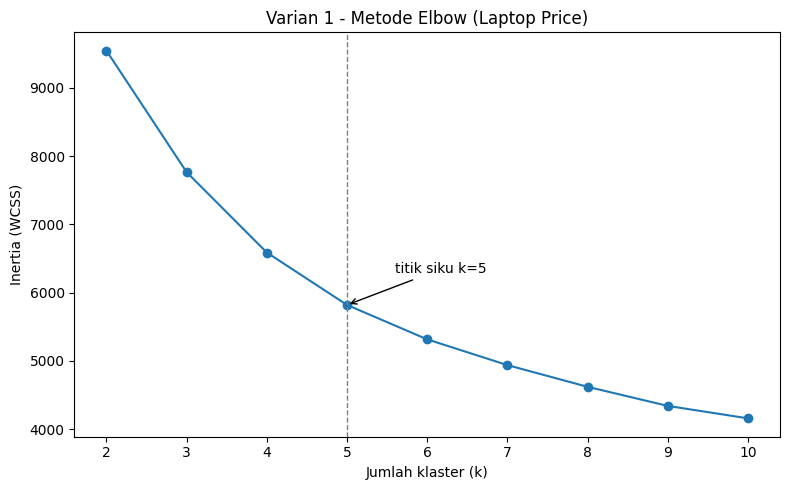


=== CEK KEBERHASILAN ===
✅ Gambar BERHASIL disimpan di: /content/drive/MyDrive/ProyekML_KlasteringKMeans/gambar/varian1_elbow.png
✅ JSON BERHASIL disimpan di: /content/drive/MyDrive/ProyekML_KlasteringKMeans/data/hasil_varian/varian1.json


In [25]:
import matplotlib.pyplot as plt
import os
from alat import (jalankan_k, muat_bersih, simpan_hasil, skalakan, titik_siku)

print('=' * 70)
print('VARIAN 1 - PENENTUAN k DENGAN METODE ELBOW (LAPTOP PRICE)')
print('=' * 70)

# 1. Pastikan folder gambar ada
if not os.path.exists('gambar'):
    os.makedirs('gambar')
    print("Folder 'gambar' berhasil dibuat.")

# 2. Load data bersih
df = muat_bersih()
X, _ = skalakan(df)
print(f'Data bersih kelompok: {df.shape[0]} baris, {df.shape[1]} fitur\n')

# 3. Jalankan K-Means
tabel = jalankan_k(X)
tabel['penurunan'] = tabel['inertia'].diff().abs()
tabel['penurunan_persen'] = (tabel['penurunan'] / tabel['inertia'].shift(1) * 100)

print(tabel[['k', 'inertia', 'penurunan', 'penurunan_persen', 'silhouette']]
      .round(3).to_string(index=False))

# 4. Cari Titik Siku
k_siku = titik_siku(tabel['k'], tabel['inertia'])
sil_siku = float(tabel.loc[tabel['k'] == k_siku, 'silhouette'].iloc[0])
inertia_siku = float(tabel.loc[tabel['k'] == k_siku, 'inertia'].iloc[0])

print(f'\nTitik siku  : k = {k_siku}')
print(f'Inertia     : {inertia_siku:,.2f}')
print(f'Silhouette  : {sil_siku:.4f}  (metrik pendukung)')

# 5. Plot Grafik
plt.figure(figsize=(8, 5))
plt.plot(tabel['k'], tabel['inertia'], marker='o')
plt.axvline(k_siku, ls='--', lw=1, color='grey')
plt.annotate(f'titik siku k={k_siku}', xy=(k_siku, inertia_siku),
             xytext=(k_siku + 0.6, inertia_siku * 1.08),
             arrowprops=dict(arrowstyle='->', lw=1))
plt.xlabel('Jumlah klaster (k)'); plt.ylabel('Inertia (WCSS)')
plt.title('Varian 1 - Metode Elbow (Laptop Price)')
plt.tight_layout()

# Simpan grafik secara eksplisit ke folder gambar
path_gambar = 'gambar/varian1_elbow.png'
plt.savefig(path_gambar, dpi=110)

# Tampilkan grafik di layar Colab
plt.show()

# 6. Simpan Hasil JSON
jalur_json = simpan_hasil(1, {
    'varian': 1,
    'nama': 'Penentuan k (Metode Elbow)',
    'yang_diubah': 'Jumlah klaster ditentukan dari titik siku kurva inertia',
    'fitur_dipakai': df.columns.tolist(),
    'k_terpilih': k_siku,
    'metrik_utama': {'silhouette': round(sil_siku, 4)},
    'metrik_pendukung': {'inertia': round(inertia_siku, 2)},
    'tabel_k': tabel[['k', 'inertia', 'silhouette', 'davies_bouldin']]
                .round(4).to_dict(orient='records'),
})

# VERIFIKASI APAKAH FILE SUDAH MASUK KE DRIVE
print("\n=== CEK KEBERHASILAN ===")
if os.path.exists(path_gambar):
    print(f"✅ Gambar BERHASIL disimpan di: {os.path.abspath(path_gambar)}")
else:
    print("❌ Gambar GAGAL disimpan.")

if os.path.exists(jalur_json):
    print(f"✅ JSON BERHASIL disimpan di: {os.path.abspath(jalur_json)}")
else:
    print("❌ JSON GAGAL disimpan.")

## 2.3 Yang harus Anda tulis sendiri

Rubrik varian perorangan menilai tiga hal: **ketepatan implementasi**, **kebenaran evaluasi**, dan **kedalaman interpretasi**. Butir ketiga tidak dapat dihasilkan oleh kode, dan di situlah nilai paling banyak hilang.

1. Apa arti titik siku ini dalam konteks kasus kelompok Anda?
Dari grafik yang muncul, titik sikunya jatuh di k=5. Artinya, laptop-laptop di dataset kami ini paling natural kalau dibagi jadi 5 segmen pasar. Kalau dipikir-pikir masuk akal, mungkin 5 segmen itu kira-kira buat kategori Budget (murah), Mainstream (standar), Ultrabook (tipis ringan), Gaming (performa tinggi), sama Workstation (buat kerja berat).

2. Seberapa tegas sikunya?
Sikunya lumayan tegas sih. Bisa kelihatan garisnya turun drastis banget dari k=2 ke k=4. Pas nyampe k=5, penurunannya udah mulai landai. Jadi kalau misal ada yang mau coba k=4, sebenernya nggak salah juga, cuma k=5 ini yang paling pas di titik patahannya. Karena nambah klaster lagi setelah angka 5 udah nggak ngefek banyak.

3. Apa yang berubah pada aplikasi web bila k Anda yang dipakai?
Kalau nanti k=5 ini dipakai buat aplikasi web, nanti hasil di layar user bakal muncul 5 label segmen yang beda-beda (bukan cuma sekadar angka 1-5, tapi nanti ada namanya). Jadi user masukin spek laptopnya, terus aplikasinya bakal ngasih tahu 'laptop kamu masuk segmen Gaming' atau 'segmen Budget' gitu.


## 2.4 Unduh, commit, dan teruskan

In [29]:
# Unduh hasil Bagian 2, lalu commit ke repositori dengan akun GitHub
# ANDA SENDIRI. Riwayat commit adalah bukti penilaian perorangan.
from google.colab import files
files.download('data/hasil_varian/varian1.json')
files.download('gambar/varian1_elbow.png')
print()
print('Langkah berikutnya:')
print('  1. Commit kedua berkas di atas dengan akun GitHub Anda sendiri.')
print('  2. File -> Download -> Download .ipynb, beri nama 03_varian_1.ipynb,')
print('     lalu commit ke folder notebook/.')
print('  3. Teruskan `varian1.json` ke Anggota 2.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Langkah berikutnya:
  1. Commit kedua berkas di atas dengan akun GitHub Anda sendiri.
  2. File -> Download -> Download .ipynb, beri nama 03_varian_1.ipynb,
     lalu commit ke folder notebook/.
  3. Teruskan `varian1.json` ke Anggota 2.


## Checklist Bagian 2

- ✅ `varian1.json` ter-commit di `data/hasil_varian/`
- ✅ `varian1_elbow.png` ter-commit di `gambar/`
- ✅ Notebook ini diunduh, diberi nama `03_varian_1.ipynb`, dan ter-commit di `notebook/`
- ✅ Commit dilakukan dengan akun GitHub Anggota 1 sendiri
- ✅ Ketiga jawaban di 2.3 sudah ditulis
- ✅ `varian1.json` sudah dikirim ke Anggota 2